In [74]:
import numpy as np
import pandas as pd
import os, glob, re, math, shutil, pysam, subprocess
import scipy
from Bio import Seq, SeqIO
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import hvplot.pandas
import matplotlib
import matplotlib.dates as mdates
from pathlib import Path
from matplotlib.patches import Rectangle
from shapely import wkt
import networkx as nx
from geopy.distance import geodesic

df_collection_metadata = pd.read_csv("./data/collection_metadata.csv")
df_PN_collection_metadata = pd.read_csv("./data/Pulse_Net_samples_dates.csv")

df_PN_metadata = pd.read_csv("data/from_Reed/101526_pnusa.csv")[['county_name', 'sample_type', 'Sequence ID']].rename(columns={'county_name': 'County', 'Sequence ID': 'acc_id'})
df_PN_metadata = df_PN_metadata.merge(df_PN_collection_metadata[['Query', 'collection_date']].rename(columns={'Query': 'acc_id'}), on='acc_id')

mlst_profiles = pd.read_csv("references/mlst_profiles.tsv", sep='\t')

In [4]:
df_blinded_samples = pd.read_excel("data/from_Reed/blinded_biosamples_listeria_test 1.xlsx").drop_duplicates()
print(len(df_blinded_samples))
df_blinded_samples[['BioSample']].to_csv("./data/from_Reed/blinded_biosamples_listeria.csv", index=False, header=None)

74


In [5]:
df_SRA = pd.read_csv("data/blinded_biosamples_listeria_SRA.csv")
print(len(df_SRA), sum(pd.isnull(df_SRA['Run'])))

df_SRA = df_SRA.dropna(subset='Run').drop_duplicates(subset=['BioSample', 'Run']).reset_index(drop=True)
print(len(df_SRA), df_SRA.BioSample.nunique(), df_SRA.Run.nunique())

77 4
72 70 72


In [6]:
# SRR1553830 is contaminated with Salmonella. Idk why there are 2 runs for SAMEA2604669, both are clean and give the same lineage/CC results
df_SRA.iloc[df_SRA.index.values[df_SRA.duplicated(subset='BioSample', keep=False)]].sort_values('BioSample')[['BioSample', 'Run', 'CenterName', 'LibraryName', 'SampleName']]

,BioSample,Run,CenterName,LibraryName,SampleName
8,SAMEA2604669,ERR538110,IFH_MS,unspecified,SAMEA2604669
9,SAMEA2604669,ERR538111,IFH_MS,unspecified,SAMEA2604669
20,SAMN02769700,SRR1481686,CFSAN,Listeria monocytogenes str. MOD1_LS147 shotgun,MOD1_LS147
21,SAMN02769700,SRR1553830,CFSAN,Listeria monocytogenes str. MOD1_LS147 shotgun,MOD1_LS147


In [29]:
samples_no_FQ = list(set(df_blinded_samples.BioSample) - set(df_SRA.BioSample))
len(samples_no_FQ)

4

In [22]:
# df_SRA.query("BioSample=='SAMN52830594'")[['Query', 'Run']].rename(columns={'Query': 'SampleName'}).to_csv("check_samples.csv", index=False)

In [43]:
df_no_FQ = pd.DataFrame({'SampleName': ['SAMEA2272177', 'SAMEA2272406', 'SAMEA2272785', 'SAMN10230511'],
                         'Run': [np.nan]*4
                        }).to_csv("check_samples.csv", index=False)

In [45]:
df_SRA[['BioSample', 'Run']].to_csv("./data/blinded_samples.csv", index=False)

In [67]:
# df_SRA.query("Run in ['ERR538110', 'SRR1553830']")[['Query', 'Run']].rename(columns={'Query': 'SampleName'}).to_csv("contam_samples.csv", index=False)

In [32]:
df_SRA.query("BioSample=='SAMN52830594'")[['Query', 'Run']].rename(columns={'Query': 'SampleName'}).to_csv("check_samples.csv", index=False)

In [149]:
# df_SRA.sort_values('size_MB', ascending=False)

In [13]:
# for sample in df_SRA.Query.unique():
#     try:
#         os.makedirs(f"results/{sample}", exist_ok=True)
#         # subprocess.run(f"gcloud storage cp gs://bact-outbreak-1-nysdohwc/sanjana/Listeria/blinded_test/{sample}/strain_typing/lineage_CC.csv results/{sample}/strain_typing/lineage_CC.csv", shell=True)
#     except:
#         print(f"{sample} failed")

In [129]:
df_strain_typing_blinded = []

for fName in glob.glob(f"results/S*/strain_typing/lineage_CC.csv"):
    df = pd.read_csv(fName)
    df['Sample'] = os.path.basename(os.path.dirname(os.path.dirname(fName)))
    df_strain_typing_blinded.append(df)

df_strain_typing_blinded = pd.concat(df_strain_typing_blinded).reset_index(drop=True)
print(len(df_strain_typing_blinded), df_strain_typing_blinded.Sample.nunique())

df_strain_typing_blinded['CC_num'] = df_strain_typing_blinded['CC'].str.replace('CC', '').str.replace('ST', '')
df_strain_typing_blinded['ST'] = df_strain_typing_blinded['ST'].astype(str)

74 74


In [128]:
df_strain_typing_blinded.CC.nunique(), df_strain_typing_blinded.ST.nunique()

(35, 41)

In [130]:
set(df_SRA.Query) - set(df_strain_typing_blinded.Sample)

set()

In [131]:
df_strain_typing_blinded.Lineage.value_counts(dropna=False)

Lineage
II     28
I      23
III    17
IV      6
Name: count, dtype: int64

In [50]:
# df_strain_typing_blinded[['Sample', 'Lineage', 'CC']].to_csv("./blinded_samples_results.csv", index=False)#, 'abcZ', 'bglA', 'cat', 'dapE', 'dat', 'ldh', '']]

In [132]:
df_strain_typing_actual = pd.read_csv("./data/from_Reed/blinded_samples_results_wmlst.csv").dropna()

# df_strain_typing_actual['CC_num'] = df_strain_typing_actual['CC'].str.replace('CC', '').str.replace('ST', '')
df_strain_typing_actual['MLST'] = df_strain_typing_actual['MLST'].astype(int).astype(str)

# # these are the ones from Reed's results
# wrong_mlst = df_strain_typing_actual.query("CC_num != MLST").MLST.unique()
# wrong_mlst = [f'CC{num}' for num in wrong_mlst]

# df_strain_typing_actual = df_strain_typing_actual.merge(df_strain_typing_blinded[['Sample', 'ST']])
# df_strain_typing_actual['ST'] = df_strain_typing_actual['ST'].astype(str)

len(df_strain_typing_actual)

63

In [138]:
df_strain_typing_blinded[['Sample', 'ST']].merge(df_strain_typing_actual, on='Sample').query("ST != MLST")

,Sample,ST,Lineage,CC,MLST


In [27]:
for i, row in df_strain_typing_blinded.iterrows():
    sample = row['Sample']
    
    if os.path.isfile(f"results/{sample}/quast_report.tsv"):
        df = pd.read_csv(f"results/{sample}/quast_report.tsv", sep='\t')
        genome_length = df.loc[df['Assembly']=='Total length (>= 0 bp)', 'filtered_contigs'].values[0]
        df_strain_typing_blinded.loc[i, 'Length'] = genome_length
        
    elif os.path.isfile(f"results/{sample}/assembly/quast/report.tsv"):
        df = pd.read_csv(f"results/{sample}/assembly/quast/report.tsv", sep='\t')
        genome_length = df.loc[df['Assembly']=='Total length (>= 0 bp)', 'assembly'].values[0]
        df_strain_typing_blinded.loc[i, 'Length'] = genome_length
        
    else:
        print(f"No quast report for {sample}")

No quast report for SAMEA3878255


In [29]:
df_strain_typing_blinded.sort_values('Length')

,abcZ,bglA,cat,dapE,dat,ldh,lhkA,ST,CC,Lineage,Sample,Length
8,67,76,91,102,60,228,38,564,ST564,IV,SAMN03277818,2727014.0
2,456,75,93,101,61,657,394,2662,CC2662,IV,SAMN02463169,2762158.0
16,83,19,91,100,58,178,72,562,CC562,IV,SAMN03277817,2763507.0
17,92,117,199,113,157,380,170,1180,CC1180,III,SAMN03277819,2789987.0
58,32,58,72,24,25,123,55,1510,CC1510,III,SAMN03013643,2808460.0
...,...,...,...,...,...,...,...,...,...,...,...,...
38,5,6,2,9,5,3,1,8,CC8,II,SAMEA112301290,3047360.0
43,2,1,11,3,3,1,7,5,CC5,I,SAMN03755578,3061795.0
7,2,1,11,3,3,1,7,5,CC5,I,SAMN03755382,3063855.0
14,7,15,15,78,6,14,9,431,CC101,II,SAMN52830594,3360834.0


<Axes: xlabel='Length', ylabel='Count'>

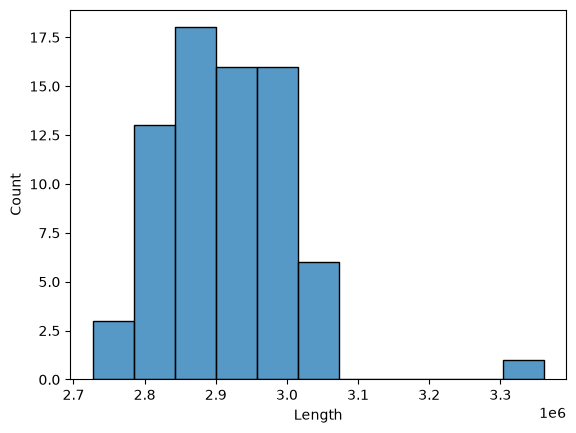

In [30]:
sns.histplot(data=df_strain_typing_blinded,
             x='Length'
            )

In [53]:
df_strain_typing_blinded.query("Sample==@sample")

,abcZ,bglA,cat,dapE,dat,ldh,lhkA,ST,CC,Lineage,Sample,Length
14,7,15,15,78,6,14,9,431,CC101,II,SAMN52830594,3360834.0


In [47]:
sample = 'SAMN52830594'
# sample = 'SAMN52830594'
depth_file = f"results/{sample}/alignment/{sample}.depth.tsv.gz"
classifications_file = f"results/{sample}/kraken/classifications.tsv"
mlst_file = f"results/{sample}/strain_typing/mlst.csv"
contigs_file = f"results/{sample}/assembly/contigs.fasta"

df_contigs = pd.DataFrame([(seq.id, seq.seq) for seq in SeqIO.parse(contigs_file, "fasta")])
df_contigs.columns = ['Isolate', 'Seq']

df_mlst_profiles = pd.read_csv("references/mlst_profiles.tsv", sep='\t')

df_mlst = pd.read_csv(mlst_file)
df_mlst_allele_nums = df_mlst['ALLELES'].str.findall(r'\(~?(\d+)(?:,(\d+))?\)').apply(lambda x: pd.Series([','.join(dict.fromkeys(filter(None, pair))) for pair in x])).astype(str)
df_mlst_allele_nums.columns = df_mlst['ALLELES'].str.findall(r'([a-zA-Z]+)\(').apply(pd.Series).iloc[0, :].values

# because of the possibility of values like 6,5, the numbers in df_mlst_allele_nums are strings, but the numbers in df_mlst_profiles are integers. So need to convert
df_mlst_profiles[df_mlst_allele_nums.columns] = df_mlst_profiles[df_mlst_allele_nums.columns].astype(str)

# merge with the profiles file.
df_merged = df_mlst_allele_nums.merge(df_mlst_profiles, on=list(df_mlst_allele_nums.columns))

df_depth = pd.read_csv(depth_file, sep="\t", header=None, names=['Contig', 'Position', 'Depth'], compression='infer')

df_depth_summary = pd.DataFrame(df_depth.groupby('Contig')['Depth'].median()).reset_index()
    
# # keep contigs with at least a length of contig_min_length and median coverage of contig_min_median_cov
# # and merge dataframes to filter both at the same time
# df_keep_contigs = df_contigs.query("Length >= @min_contig_length").merge(df_depth.groupby('Contig')['Depth'].agg(['mean', 'median']).reset_index().query("median >= @min_median_coverage"), on='Contig')

# then IF AND ONLY IF the total classified length to the target species is >95% of the total length (after filtering by contig length and coverage), further filter and keep
df_kraken = pd.read_csv(classifications_file, sep='\t', header=None, names=['Classified', 'Contig', 'TaxName', 'Length', 'All_Taxa'])

# # separate taxid and name
# df_kraken["TaxID"] = (df_kraken["TaxName"].str.extract(r"\(taxid (\d+)\)")[0]).astype(int)
# df_kraken["TaxName"] = (df_kraken["TaxName"].str.replace(r"\s*\(taxid \d+\)$", "", regex=True))
    
# df_contigs_classifications = df_keep_contigs.merge(df_kraken, on=['Contig', 'Length'])
# assert len(set(df_keep_contigs.Contig) - set(df_contigs_classifications.Contig)) == 0

In [34]:
df_kraken.query("Length >= 500 & TaxName.str.contains('Listeria')").Length.sum()

np.int64(3354763)

In [46]:
df_kraken.query("Length >= 500 & TaxName.str.contains('Listeria')").merge(df_depth_summary, on='Contig').sort_values(['Length', 'Depth'], ascending=[False, False])

,Classified,Contig,TaxName,Length,All_Taxa,Depth
0,C,NODE_1_length_637246_cov_16.553967,Listeria monocytogenes WSLC1001 (taxid 1457187),637246,1:1 0:5 1:9 0:6 1385:3 0:43 1639:2 0:13 178327...,19.0
1,C,NODE_2_length_585516_cov_17.405648,Listeria monocytogenes Finland 1998 (taxid 393...,585516,0:38 1:7 0:7 1639:2 0:46 1639:8 0:6 1639:5 0:3...,40.0
2,C,NODE_3_length_542503_cov_17.693720,Listeria monocytogenes FSL R2-561 (taxid 393126),542503,0:21 1783272:5 0:11 1637:5 0:5 1637:3 0:23 163...,40.0
3,C,NODE_4_length_440213_cov_18.387013,Listeria monocytogenes EGD-e (taxid 169963),440213,0:36 1639:2 0:19 1639:6 0:22 1639:6 0:9 1639:3...,42.0
4,C,NODE_5_length_194142_cov_17.694400,Listeria monocytogenes (taxid 1639),194142,0:90 1639:5 0:5 1639:5 0:22 1639:1 0:4 1639:2 ...,41.0
5,C,NODE_6_length_181555_cov_17.032193,Listeria monocytogenes Finland 1998 (taxid 393...,181555,0:66 1:3 0:24 1:1 0:2 1:14 0:47 1:3 0:21 1:5 0...,39.0
6,C,NODE_7_length_163497_cov_18.434038,Listeria monocytogenes serotype 7 str. SLCC248...,163497,0:2 1639:5 0:55 1639:5 0:9 1639:1 0:19 1639:1 ...,42.0
7,C,NODE_8_length_128996_cov_18.917738,Listeria monocytogenes (taxid 1639),128996,0:2 1637:1 0:18 1637:2 0:46 1385:5 2:2 0:10 13...,43.0
8,C,NODE_9_length_113739_cov_18.129860,Listeria monocytogenes (taxid 1639),113739,1639:3 0:14 1637:5 0:12 1637:1 0:14 1637:5 0:1...,42.0
9,C,NODE_10_length_98936_cov_16.641832,Listeria monocytogenes (taxid 1639),98936,0:10 1637:7 0:40 1639:2 0:21 1639:5 0:37 1637:...,38.0


In [51]:
contig_name = 'NODE_20_length_3123_cov_64.859844'

str(df_contigs.query("Isolate==@contig_name").Seq.values[0])

'ATAATTTATTATTTATGACACAAGTAACCGAGAATCATCTGAAAGTGAATCTTTCATCTGATTGGATGTATCATCGCTGATACGGAAAATCAGAAAAACAACCTTTACTTCGTAGAAGTAAATTGGTTAAGTTAGAAAGGGCGCACGGTGGATGCCTTGGCACTAGGAGCCGAAGAAGGACGGGACTAACACCGATATGCTTTGGGGAGCTGTACGTAAGCGTTGATCCAGAGATTTCCGAATGGGGGAACCCACTATCTTTAGTCGGATAGTATCCTTACGTGAATACATAGCGTGAGGAAGGCAGACCCAGGGAACTGAAACATCTAAGTACCTGGAGGAAGAGAAAGAAAAATCGATTTCCTGAGTAGCGGCGAGCGAAACGGAAAGAGCCCAAACCAAGAAGCTTGCTTCTTGGGGTTGTAGGACACTCTATACGGAGTTACAAAAGAAAGTTATAAATGAAGCGGTCTGGAAAGGCCCGCCAAAGACGGTAACAGCCCGGTAGTTGAAATAGCTTTCCCTCCAGAGTGGATCCTGAGTACGGCGGAACACGTGAAATTCCGTCGGAATCCGGGAGGACCATCTCCCAAGGCTAAATACTCCCTAGTGACCGATAGTGAACCAGTACCGTGAGGGAAAGGTGAAAAGCACCCCGGAAGGGGAGTGAAACAGTTCCTGAAACCGTGTGCCTACAAGTAGTTAGAGCCCGTTAATGGGTGATAGCGTGCCTTTTGTAGAATGAACCGGCGAGTTACGATTTGTTGCAAGGTTAAGCGGAAAAAGCGGAGCCGTAGCGAAAGCGAGTCTGAATAGGGCGCATAAGTAACAGGTCGTAGACCCGAAACCAGGTGATCTACCCATGTCCAGGATGAAGGTAAGGTAATACTTACTGGAGGTCCGAACCCACGCACGTTGAAAAGTGCGGGGATGAGGTGTGGGTAGCGGAGAAATTCCAATCGAACTTGGAGATAGCTGGTTCTCTCCGAAATAGCTTTA

In [114]:
df_mlst.ALLELES.values

<StringArray>
['abcZ(18);bglA(11);cat(21);dapE(24);dat(17);ldh(35);lhkA(13)']
Length: 1, dtype: str

In [91]:
df_kraken.query("TaxName.str.contains('Listeria')")

,Classified,Contig,TaxName,Length,All_Taxa
0,C,NODE_1_length_637246_cov_16.553967,Listeria monocytogenes WSLC1001 (taxid 1457187),637246,1:1 0:5 1:9 0:6 1385:3 0:43 1639:2 0:13 178327...
1,C,NODE_2_length_585516_cov_17.405648,Listeria monocytogenes Finland 1998 (taxid 393...,585516,0:38 1:7 0:7 1639:2 0:46 1639:8 0:6 1639:5 0:3...
2,C,NODE_3_length_542503_cov_17.693720,Listeria monocytogenes FSL R2-561 (taxid 393126),542503,0:21 1783272:5 0:11 1637:5 0:5 1637:3 0:23 163...
3,C,NODE_4_length_440213_cov_18.387013,Listeria monocytogenes EGD-e (taxid 169963),440213,0:36 1639:2 0:19 1639:6 0:22 1639:6 0:9 1639:3...
4,C,NODE_5_length_194142_cov_17.694400,Listeria monocytogenes (taxid 1639),194142,0:90 1639:5 0:5 1639:5 0:22 1639:1 0:4 1639:2 ...
...,...,...,...,...,...
90,C,NODE_91_length_97_cov_7.976190,Listeria monocytogenes (taxid 1639),97,0:13 1639:5 0:36 1637:5 0:4
93,C,NODE_94_length_86_cov_25.032258,Listeriaceae (taxid 186820),86,0:9 2:4 0:5 186820:4 1783272:1 0:4 186820:2 0:23
94,C,NODE_95_length_86_cov_18.709677,Listeria monocytogenes (taxid 1639),86,0:4 1639:1 0:30 1639:5 0:6 1639:6
100,C,NODE_101_length_59_cov_22.500000,Listeria monocytogenes (taxid 1639),59,0:8 1639:5 0:6 1639:6


In [2]:
samples = os.listdir("results")
len(samples)

366

In [5]:
uploaded_moap = pd.read_csv("../uploaded_moap.txt", sep='\t', header=None)

In [11]:
uploaded_moap['Sample'] = [re.search(r'/Lmo/([^/]+)/', path).group(1) for path in uploaded_moap[0].values]

In [13]:
uploaded_moap.Sample.nunique()

364

In [14]:
set(samples) - set(uploaded_moap.Sample)

{'EHS2500082385-01-01', 'PNUSAL015001'}

# Assembly Statistics

In [2]:
df_assembly_stats = []

for sample in os.listdir("results"):

    df_stats = pd.read_csv(f"results/{sample}/assembly/quast/report.tsv", sep='\t')[['Assembly', 'filtered_contigs']]
    df_stats = df_stats.set_index('Assembly').T[['# contigs', 'Largest contig', 'Total length', 'GC (%)', 'N50', 'N90', 'L50', 'L90']]
    df_stats.index = [sample]
    df_assembly_stats.append(df_stats)

df_assembly_stats = pd.concat(df_assembly_stats).reset_index()

In [3]:
def print_min_median_max(df, var, var_name):

    print(var_name)

    print(f"    Min: {df[var].min():,}")
    print(f"    Median: {df[var].median():,}")
    print(f"    Max: {df[var].max():,}")

In [4]:
print_min_median_max(df_assembly_stats, 'Total length', 'Length')

Length
    Min: 2,813,573.0
    Median: 2,910,714.0
    Max: 3,166,251.0


In [5]:
print_min_median_max(df_assembly_stats, '# contigs', 'Number of Contigs')

Number of Contigs
    Min: 7.0
    Median: 17.0
    Max: 52.0


In [6]:
print_min_median_max(df_assembly_stats, 'Largest contig', 'Longest Contig')

Longest Contig
    Min: 281,071.0
    Median: 932,212.5
    Max: 1,549,611.0


In [7]:
print_min_median_max(df_assembly_stats, 'N50', 'N50')

N50
    Min: 135,081.0
    Median: 474,733.0
    Max: 1,549,611.0


In [8]:
print_min_median_max(df_assembly_stats, 'L50', 'L50')

L50
    Min: 1.0
    Median: 2.0
    Max: 8.0


# Strain Typing

In [376]:
df_metadata = []

for sample in os.listdir("results"):

    df_mlst = pd.read_csv(f"results/{sample}/strain_typing/mlst.csv")
    df_lineage = pd.read_csv(f"results/{sample}/strain_typing/lineage_CC.csv")

    # prioritize the results from the Pasteur table because the mlst tool results include the ~, meaning some won't get typed
    # ~N means it's the same length as that allele and by default ≥95% identity. I think that's close enough, so we're considering it the same
    del df_mlst['ST']
    df_mlst['Sample'] = sample

    if len(df_lineage) > 1:
        # there are multiple CCs that are equidistant, so return them all?
        combined_CC = ','.join(np.sort(df_lineage.CC.unique()))
        df_lineage['CC'] = combined_CC

        # then just keep 1 row?
        print(f"{sample} is equidistant from {df_lineage.CC.nunique()} CCs: {combined_CC}")
        df_lineage = df_lineage.iloc[[0], :]

    df_mlst = pd.concat([df_mlst, df_lineage[['ST', 'CC', 'Lineage']]], axis=1)
    
    # skip the first column, which is the file name
    df_metadata.append(df_mlst.iloc[:, 1:])

df_metadata = pd.concat(df_metadata)

df_split_alleles = df_metadata['ALLELES'].str.split(';', expand=True)

# make the gene names the column names
gene_names = df_split_alleles.iloc[0].dropna().astype(str).str.split('(').str[0].tolist()
df_split_alleles.columns = gene_names

# then remove the gene names from the values, leaving just the numbers
df_split_alleles = df_split_alleles.apply(lambda col: col.str.extract(r'\((\d+)\)', expand=False))

df_metadata = pd.concat([df_metadata, df_split_alleles], axis=1)
df_metadata['acc_id'] = df_metadata['Sample'].str.split('-').str[0]

df_metadata = df_metadata.merge(pd.concat([df_collection_metadata, df_PN_metadata]), how='left')

df_metadata['Collection date'] = pd.to_datetime(df_metadata['Collection date'], format='mixed')

df_metadata['WWTP_Cases'] = df_metadata.groupby('WWTP')['Sample'].transform(lambda x: x.count())

# print(f"{len(df_metadata.loc[pd.isnull(df_metadata['Lineage'])])}/{len(df_metadata)} samples don't have lineage and CC typing")


PNUSAL026439 is equidistant from 1 CCs: CC131,CC440,ST1003
IDR2400055889-04-03 is equidistant from 1 CCs: CC1553,ST1769,ST1871
EHS2600010400-01-00 is equidistant from 1 CCs: CC268,ST1197,ST1660,ST1684,ST1719,ST1883,ST1914,ST2256,ST2320,ST2618,ST265
PNUSAL025548 is equidistant from 1 CCs: CC570
EHS2500089139-01-00 is equidistant from 1 CCs: CC31
PNUSAL026469 is equidistant from 1 CCs: CC131,CC440,ST1003
PNUSAL026356 is equidistant from 1 CCs: CC131,CC440,ST1003
EHS2500002739-01-01 is equidistant from 1 CCs: CC155,ST1514
PNUSAL026357 is equidistant from 1 CCs: CC131,CC440,ST1003


In [404]:
df_metadata.query("CC.str.contains(',')").CC.value_counts()

CC
CC131,CC440,ST1003                                                            4
CC1553,ST1769,ST1871                                                          1
CC268,ST1197,ST1660,ST1684,ST1719,ST1883,ST1914,ST2256,ST2320,ST2618,ST265    1
CC155,ST1514                                                                  1
Name: count, dtype: int64

In [405]:
df_metadata.query("CC=='CC131,CC440,ST1003'")['ALLELES'].unique()

<StringArray>
['abcZ(20);bglA(33);cat(21);dapE(83);dat(17);ldh(31);lhkA(56)']
Length: 1, dtype: str

In [407]:
df_metadata.query("CC=='CC131,CC440,ST1003'")[['Sample'] + gene_names + ['CC', 'Lineage']].merge(df_PN_metadata.rename(columns={'acc_id': 'Sample'}))

,Sample,abcZ,bglA,cat,dapE,dat,ldh,lhkA,CC,Lineage,County,sample_type,collection_date
0,PNUSAL026439,20,33,21,83,17,31,56,"CC131,CC440,ST1003",III,Nassau,Blood,2026
1,PNUSAL026469,20,33,21,83,17,31,56,"CC131,CC440,ST1003",III,Suffolk,Blood,2026
2,PNUSAL026356,20,33,21,83,17,31,56,"CC131,CC440,ST1003",III,Suffolk,Blood,2026
3,PNUSAL026357,20,33,21,83,17,31,56,"CC131,CC440,ST1003",III,Suffolk,Blood,2026


In [399]:
novel_samples = df_metadata.query("CC=='CC131,CC440,ST1003'").Sample.values

df_PN_metadata.query("acc_id in @novel_samples")

,County,sample_type,acc_id,Query,collection_date
210,Suffolk,Blood,PNUSAL026357,PNUSAL026357,2026
211,Suffolk,Blood,PNUSAL026356,PNUSAL026356,2026
213,Nassau,Blood,PNUSAL026439,PNUSAL026439,2026
214,Suffolk,Blood,PNUSAL026469,PNUSAL026469,2026


In [403]:
df_metadata.Lineage.value_counts(dropna=False)

Lineage
I      236
II     117
III     13
Name: count, dtype: int64

In [13]:
def read_in_county_map(county_map_gejson_file, state_map_gejson_file):

    ny_counties = gpd.read_file(county_map_gejson_file)#.to_crs("EPSG:3857")
    us_states = gpd.read_file(state_map_gejson_file)#.to_crs("EPSG:3857")

    ny_counties['county_name'] = ny_counties['name'].str.replace(' County', '')
    
    return ny_counties, us_states.rename(columns={'STUSPS': 'state'})
    
    
ny_counties, us_states = read_in_county_map("../Dashboards/reuse/data/new-york-counties.geojson", "../Dashboards/reuse/data/us-states.geojson")

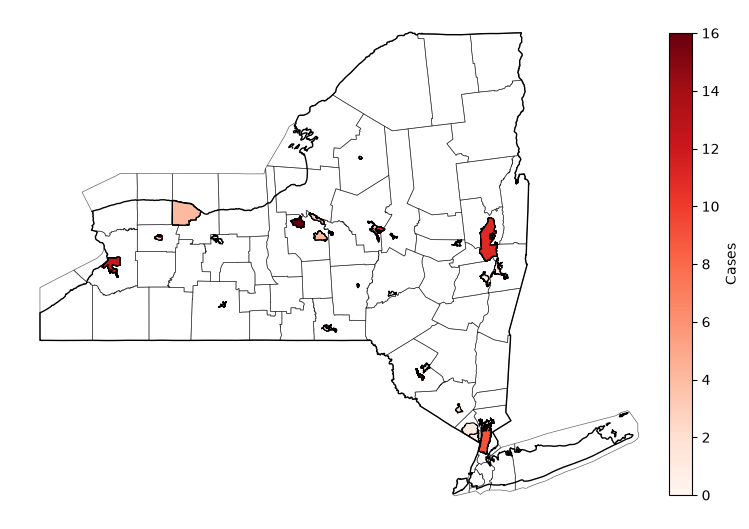

In [8]:
# df_metadata['Log_WWTP_Cases'] = np.log10(df_metadata['WWTP_Cases'] + 1)
df_WW_metadata = df_metadata.loc[~pd.isnull(df_metadata['WWTP'])]
df_WW_metadata["geometry"] = df_WW_metadata["geometry"].apply(wkt.loads)

fig, ax = plt.subplots(figsize=(10, 10))

df_map_plot = gpd.GeoDataFrame(df_WW_metadata, geometry="geometry", crs="EPSG:4326")

df_map_plot.plot(column='WWTP_Cases',
                legend=True,
                cmap='Reds',
                linewidth=0.8,
                edgecolor='black',
                vmin=0,
                ax=ax,
                legend_kwds={
                            "shrink": 0.6,  # 0.5 makes it half the height of the map
                            "pad": 0
                        },
               )

ny_counties.boundary.plot(
    ax=ax,
    color='black',
    linewidth=0.5,
    alpha=0.6
)


# Plot NY state boundary
us_states[us_states['NAME'] == 'New York'].boundary.plot(
    ax=ax,
    color='black',
    linewidth=1
)

# tick_values = [0] + [10**val for val in range(int(np.ceil(math.log10(df_map_plot['WWTP_Cases'].max()))))]
# tick_locations = np.log10(np.array(tick_values) + 1)

cbar_ax = fig.axes[-1]
# cbar_ax.set_yticks(tick_values)
# cbar_ax.set_yticklabels([f"{v:,}" for v in tick_values])

cbar_ax.set_ylabel("Cases")
sns.despine(left=True, right=True, bottom=True, top=True)
ax.axis('off')
plt.show()

# SNP and cgMLST1648 Allelic Distances

In [196]:
def convert_matrix_to_long(matrix, col_name, df_metadata):

    matrix.index.name = 'Sample1'
    matrix.columns.name = 'Sample2'
    
    df_long = matrix.where(np.triu(np.ones(matrix.shape)).astype(np.bool)).stack().reset_index().dropna().rename(columns={0: col_name})
    df_long[col_name] = df_long[col_name].astype(int)
    
    df_long['acc_id1'] = df_long['Sample1'].str.split('-').str[0]
    df_long['acc_id2'] = df_long['Sample2'].str.split('-').str[0]
    
    # df_long = df_long.query(f"~((Sample1 == Sample2) | (acc_id1 == acc_id2 & {col_name} == 0))").reset_index(drop=True)
    df_long = df_long.query("Sample1 != Sample2").reset_index(drop=True)

    metadata_cols = ['Sample', 'CC', 'Lineage', 'Collection date', 'WWTP', 'County', 'wwtp_latitude', 'wwtp_longitude', 'geometry']
    df_long = df_long.merge(df_metadata[metadata_cols].rename(columns={col: f"{col}1" for col in metadata_cols})).merge(df_metadata[metadata_cols].rename(columns={col: f"{col}2" for col in metadata_cols}))
    
    df_long['Same_CC'] = (df_long['CC1']==df_long['CC2']).astype(int)
    df_long['Same_Lineage'] = (df_long['Lineage1']==df_long['Lineage2']).astype(int)
    
    df_long.loc[pd.isnull(df_long['Lineage1']) | pd.isnull(df_long['Lineage2']), 'Same_Lineage'] = np.nan
    df_long.loc[pd.isnull(df_long['CC1']) | pd.isnull(df_long['CC2']), 'Same_CC'] = np.nan
    
    df_long.loc[(df_long['Same_CC']==0) & (df_long['Same_Lineage']==1), 'Group'] = 'Same Lineage Only'
    df_long.loc[(df_long['Same_CC']==1) & (df_long['Same_Lineage']==1), 'Group'] = 'Same CC and Lineage'
    df_long.loc[(df_long['Same_CC']==0) & (df_long['Same_Lineage']==0), 'Group'] = 'Different CC and Lineage'

    df_long['Collection_date_diff_days'] = np.abs((df_long['Collection date1'] - df_long['Collection date2']).dt.days)
    
    coord_cols = [
        "wwtp_latitude1", "wwtp_longitude1",
        "wwtp_latitude2", "wwtp_longitude2"
    ]
    
    df_long["WWTP_dist_miles"] = df_long.apply(
        lambda row: geodesic(
            (row["wwtp_latitude1"], row["wwtp_longitude1"]),
            (row["wwtp_latitude2"], row["wwtp_longitude2"])
        ).miles
        if row[coord_cols].notna().all()
        else np.nan,
        axis=1
    )

    return df_long

In [197]:
df_allele_typing = pd.concat([pd.read_csv(fName) for fName in glob.glob("data/cgmlst1758_allele_typing*.csv")])

cgmlst1748_allele_matrix = df_allele_typing.pivot(index='Sample', columns='locus', values='allele')
cgmlst1748_allele_matrix.to_csv("./data/cgmlst1748_matrix.csv")

# Calculate pairwise allelic distances
allele_dist_matrix = pd.DataFrame(
    scipy.spatial.distance.squareform(scipy.spatial.distance.pdist(cgmlst1748_allele_matrix.to_numpy(dtype=object), metric=lambda a, b: np.sum(a != b))),
    index=cgmlst1748_allele_matrix.index,
    columns=cgmlst1748_allele_matrix.index
).astype(int)

df_allele_dist = convert_matrix_to_long(allele_dist_matrix, 'Allele_Diff', df_metadata)


In [198]:
samples_no_lineage = df_metadata.loc[pd.isnull(df_metadata['Lineage'])].Sample.values
len(samples_no_lineage)

0

In [199]:
samples_inferred_lineage = {}

for sample in samples_no_lineage:

    df_sorted_dist = pd.DataFrame(allele_dist_matrix.loc[sample].sort_values()).reset_index().query("Sample2 != @sample").rename(columns={'Sample2': 'Sample'})
    df_sorted_dist = df_sorted_dist.merge(df_metadata[['Sample', 'Lineage']]).dropna(subset='Lineage')
    samples_inferred_lineage[sample] = df_sorted_dist.Lineage.values[0]

samples_inferred_lineage

{}

In [200]:
df_allele_dist['Lineage1'] = df_allele_dist['Sample1'].map(samples_inferred_lineage).fillna(df_allele_dist['Lineage1'])
df_allele_dist['Lineage2'] = df_allele_dist['Sample2'].map(samples_inferred_lineage).fillna(df_allele_dist['Lineage2'])

df_metadata['Lineage'] = df_metadata['Sample'].map(samples_inferred_lineage).fillna(df_metadata['Lineage'])

sum(pd.isnull(df_metadata['Lineage'])), sum(pd.isnull(df_allele_dist['Lineage1'])), sum(pd.isnull(df_allele_dist['Lineage2']))

(0, 0, 0)

In [205]:
df_allele_dist.query("Allele_Diff <= 20")[['Sample1', 'Lineage1', 'CC1', 'WWTP1', 'Sample2', 'Lineage2', 'CC2', 'WWTP2', 'Allele_Diff']].query("CC1 != CC2")

,Sample1,Lineage1,CC1,WWTP1,Sample2,Lineage2,CC2,WWTP2,Allele_Diff
23676,EHS2500089142-01-00,II,CC570,Southtowns,PNUSAL025548,II,NaN,NaN,5
41994,PNUSAL014088,II,CC570,NaN,PNUSAL025548,II,NaN,NaN,5
46244,PNUSAL015502,II,CC570,NaN,PNUSAL025548,II,NaN,NaN,5
66495,PNUSAL026356,III,NaN,NaN,PNUSAL026357,III,NaN,NaN,1
66496,PNUSAL026356,III,NaN,NaN,PNUSAL026439,III,NaN,NaN,1
66498,PNUSAL026356,III,NaN,NaN,PNUSAL026469,III,NaN,NaN,1
66519,PNUSAL026357,III,NaN,NaN,PNUSAL026439,III,NaN,NaN,1
66521,PNUSAL026357,III,NaN,NaN,PNUSAL026469,III,NaN,NaN,1
66543,PNUSAL026439,III,NaN,NaN,PNUSAL026469,III,NaN,NaN,1


In [219]:
df_allele_dist.query("Allele_Diff <= 20").query("~Sample1.str.startswith('PN') & ~Sample2.str.startswith('PN')")[['Sample1', 'Sample2', 'Allele_Diff', 'acc_id1', 'acc_id2', 'CC1',
       'Lineage1', 'Collection date1', 'WWTP1', 'County1', 'wwtp_latitude1',
       'wwtp_longitude1', 'CC2', 'Lineage2', 'Collection date2',
       'WWTP2', 'County2', 'wwtp_latitude2', 'wwtp_longitude2',
       'Same_CC', 'Same_Lineage', 'Group', 'Collection_date_diff_days',
       'WWTP_dist_miles']].to_csv("data/WWTP_sample_pairs_within_20_AD.csv", index=False)

In [226]:
df_allele_dist.query("acc_id1==acc_id2 & CC1 != CC2")[['CC1', 'CC2', 'Sample1', 'Sample2']]

,CC1,CC2,Sample1,Sample2
37635,CC37,NaN,IDR2400055889-04-01,IDR2400055889-04-03
37875,CC37,NaN,IDR2400055889-04-02,IDR2400055889-04-03


## Minimum Spanning Tree of Allelic Distances

In [58]:
def make_MST_allelic_distances(df_allele_dist, lineage, k_num=2, collapse_dist=0, save_fName=None):
    
    df_single_lineage = df_allele_dist.query("Lineage1 == @lineage & Lineage2 == @lineage")
    df_single_lineage_metadata = df_metadata.query("Lineage==@lineage")

    # Build original graph
    G = nx.from_pandas_edgelist(
        df_single_lineage,
        source='Sample1',
        target='Sample2',
        edge_attr='Allele_Diff'
    )

    print(f"Original graph: {G.number_of_nodes()} nodes, "
          f"{G.number_of_edges()} edges")

    # Collapse connected groups of samples within the distance threshold
    if collapse_dist > 0:
        G_close = nx.Graph()
        G_close.add_nodes_from(G.nodes())

        G_close.add_edges_from(
            (u, v)
            for u, v, d in G.edges(data=True)
            if d['Allele_Diff'] <= collapse_dist
        )

        components = list(nx.connected_components(G_close))

    else:
        components = [{node} for node in G.nodes()]

    # Map each original sample to its collapsed group
    sample_to_group = {}
    group_members = {}

    for i, component in enumerate(components):
        group = f"Group_{i}"
        group_members[group] = set(component)

        for sample in component:
            sample_to_group[sample] = group

    # Construct collapsed graph.
    # Retain the minimum original distance between each pair of groups.
    G_collapsed = nx.Graph()
    G_collapsed.add_nodes_from(group_members)

    for u, v, data in G.edges(data=True):
        group_u = sample_to_group[u]
        group_v = sample_to_group[v]

        if group_u == group_v:
            continue

        distance = data['Allele_Diff']

        if (
            not G_collapsed.has_edge(group_u, group_v)
            or distance < G_collapsed[group_u][group_v]['Allele_Diff']
        ):
            G_collapsed.add_edge(
                group_u,
                group_v,
                Allele_Diff=distance
            )

    # Minimum spanning tree of collapsed graph
    mst = nx.minimum_spanning_tree(
        G_collapsed,
        weight='Allele_Diff'
    )

    print(f"Collapsed graph: {G_collapsed.number_of_nodes()} nodes, "
          f"{G_collapsed.number_of_edges()} edges")
    print(f"MST: {mst.number_of_nodes()} nodes, "
          f"{mst.number_of_edges()} edges")

    # Map samples to metadata
    metadata = df_single_lineage_metadata.set_index('Sample')

    # Determine CC colors
    cc_counts = metadata['CC'].value_counts()
    
    if lineage == 'III':
        CCs_to_color = pd.DataFrame(df_single_lineage_metadata['CC'].value_counts()).query("count >= 1").reset_index().sort_values(['count', 'CC'], ascending=[False, True]).CC.values
        singleton_CCs = []
    else:
        CCs_to_color = pd.DataFrame(df_single_lineage_metadata['CC'].value_counts()).query("count >= 2").reset_index().sort_values(['count', 'CC'], ascending=[False, True]).CC.values
        singleton_CCs = pd.DataFrame(df_single_lineage_metadata['CC'].value_counts()).query("count == 1").index.values
        
    color_dict = dict(zip(CCs_to_color, sns.color_palette("tab20").as_hex()))
    df_single_lineage_metadata['Color'] = df_single_lineage_metadata['CC'].map(color_dict)
    
    print(color_dict)

    # Assign each collapsed node a color.
    # If all samples share one CC, use that CC's color.
    # white = no CC assigned
    # black = there is a CC, but it's a singleton
    node_colors = []
    node_labels = {}    

    for group, members in group_members.items():
        member_metadata = metadata.reindex(list(members))
        ccs = member_metadata['CC'].dropna().unique()

        if len(ccs) == 0:
            color = 'white'
        elif len(ccs) == 1:
            color = color_dict.get(ccs[0], 'black')
        else:
            # this shouldn't happen because collapse_dist is a small number, and if they are that close, then they would HAVE to be in the same CC
            raise ValueError("Multiple samples of different CC in the same collapsed group")

        node_colors.append(color)
        node_labels[group] = str(len(members)) if len(members) > 1 else ''

    # Plot
    fig, ax = plt.subplots(figsize=(14, 10))

    pos = nx.spring_layout(
        mst,
        k=k_num / np.sqrt(max(mst.number_of_nodes(), 1)),
        iterations=300,
        seed=42
    )

    nx.draw_networkx(
        mst,
        pos=pos,
        node_color=node_colors,
        labels=node_labels,
        node_size=[
            150 + 30 * (len(group_members[node]) - 1)
            for node in mst.nodes()
        ],
        edgecolors='black',
        linewidths=0.5,
        font_size=6,
        width=1,
        with_labels=True,
        ax=ax
    )

    color_dict['Singleton CC'] = 'black'
    color_dict['No CC'] = 'white'
    
    # Legend
    handles = [
        plt.Line2D(
            [0], [0],
            marker='o',
            color='w',
            markerfacecolor=color,
            markeredgecolor='black',
            markeredgewidth=0.5,
            label=cc,
            markersize=8
        )
        for cc, color in color_dict.items()
    ]
    ax.legend(handles=handles, title='Clonal Complex', loc='best')
    
    ax.set_axis_off()
    plt.tight_layout()

    if save_fName is None:
        plt.show()
    else:
        plt.savefig(save_fName, bbox_inches='tight')

    # return mst, group_members

Original graph: 236 nodes, 27730 edges
Collapsed graph: 71 nodes, 2485 edges
MST: 71 nodes, 70 edges
{'CC554': '#1f77b4', 'CC1': '#aec7e8', 'CC388': '#ff7f0e', 'CC217': '#ffbb78', 'CC389': '#2ca02c', 'CC4': '#98df8a', 'CC2': '#d62728', 'CC5': '#ff9896', 'CC6': '#9467bd', 'CC288': '#c5b0d5', 'CC87': '#8c564b', 'CC183': '#c49c94', 'CC88': '#e377c2', 'CC3': '#f7b6d2', 'CC379': '#7f7f7f', 'CC392': '#c7c7c7', 'CC639': '#bcbd22', 'ST581': '#dbdb8d'}


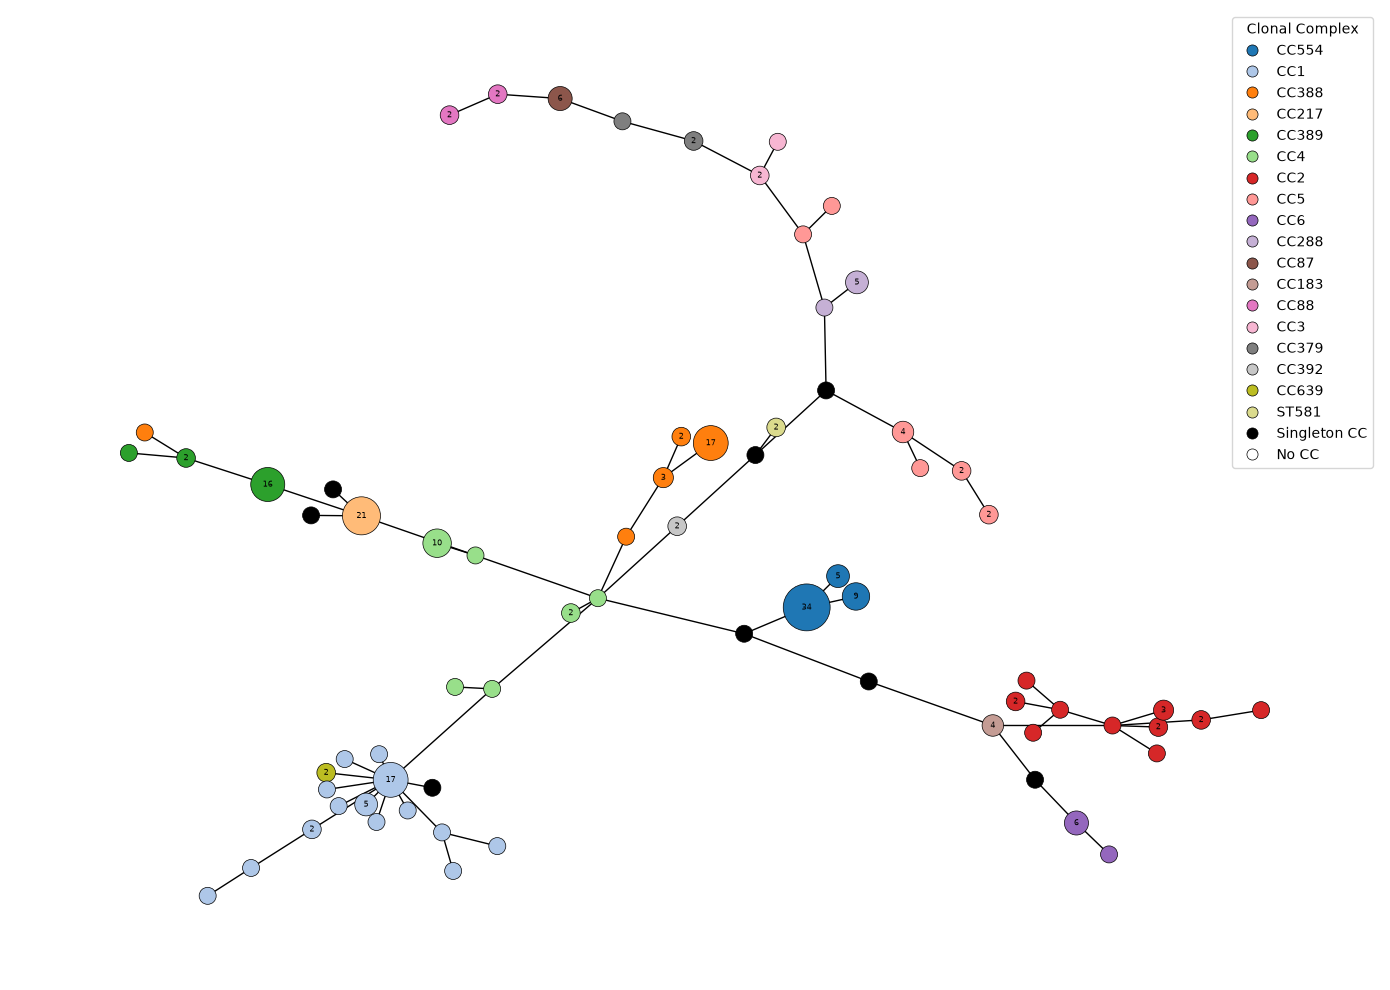

In [60]:
make_MST_allelic_distances(df_allele_dist, 'I', k_num=5, collapse_dist=30, save_fName="./phylogeny/MST/Lineage_I_allelic_distances.svg")

In [51]:
df_metadata.query("CC=='CC639'")[['Sample']]

,Sample
194,PNUSAL027068
239,EHS2600010178-01-00


Original graph: 117 nodes, 6786 edges
Collapsed graph: 78 nodes, 3003 edges
MST: 78 nodes, 77 edges
{'CC11': '#1f77b4', 'CC369': '#aec7e8', 'CC7': '#ff7f0e', 'CC155': '#ffbb78', 'CC37': '#2ca02c', 'ST795': '#98df8a', 'CC14': '#d62728', 'CC226': '#ff9896', 'CC29': '#9467bd', 'CC204': '#c5b0d5', 'CC321': '#8c564b', 'CC570': '#c49c94', 'CC101': '#e377c2', 'CC20': '#f7b6d2', 'CC8': '#7f7f7f', 'CC901': '#c7c7c7', 'ST1372': '#bcbd22'}


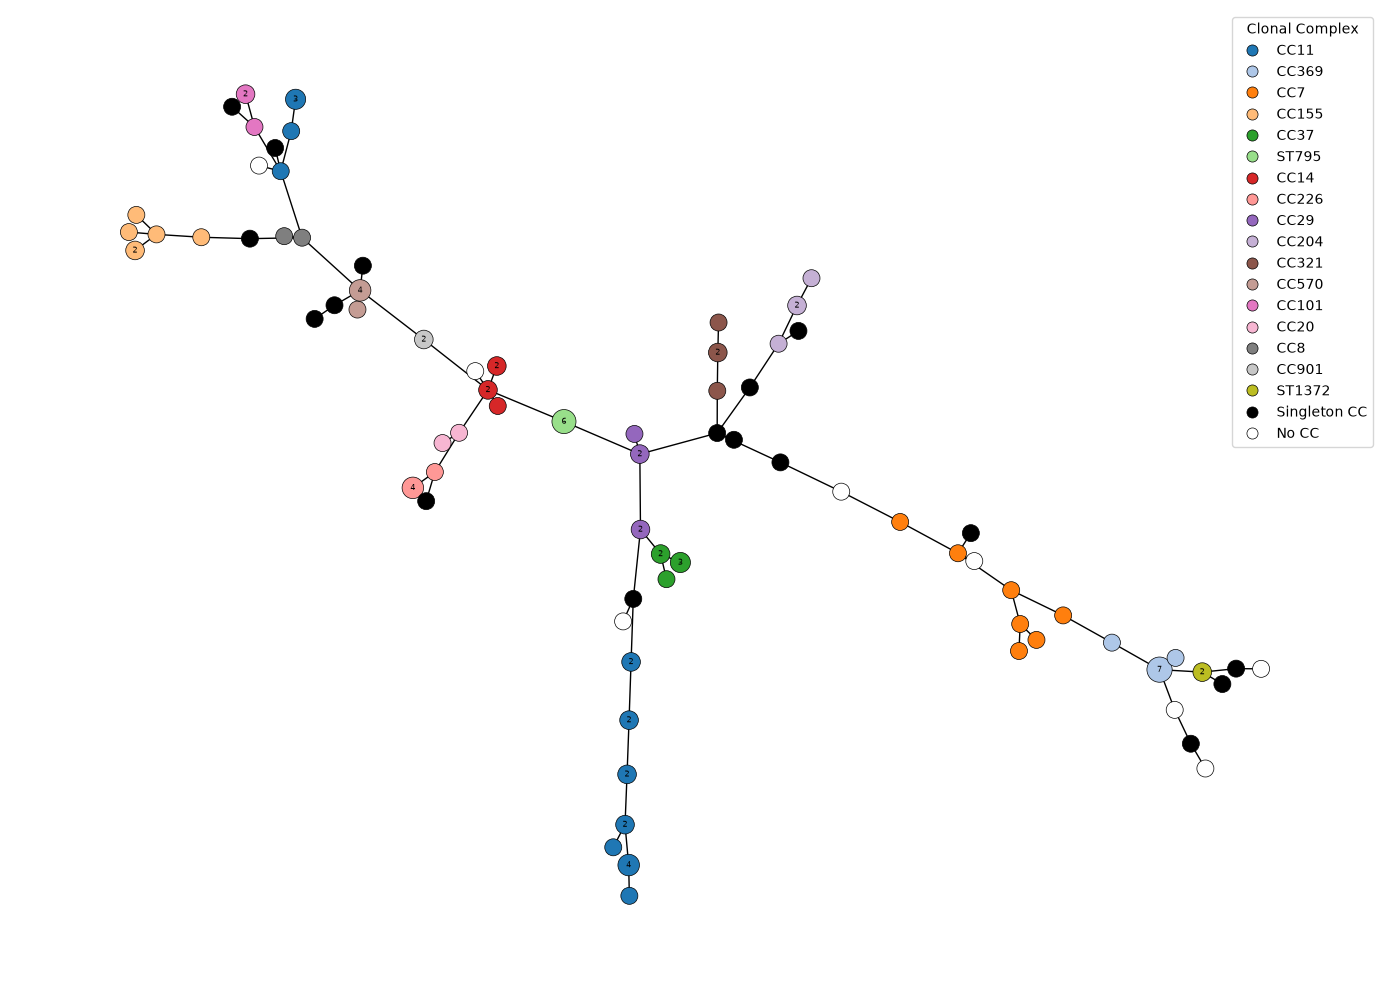

In [61]:
make_MST_allelic_distances(df_allele_dist, 'II', k_num=1, collapse_dist=10, save_fName="./phylogeny/MST/Lineage_II_allelic_distances.svg")

Original graph: 13 nodes, 78 edges
Collapsed graph: 13 nodes, 78 edges
MST: 13 nodes, 12 edges
{'CC267': '#1f77b4', 'CC669': '#aec7e8'}


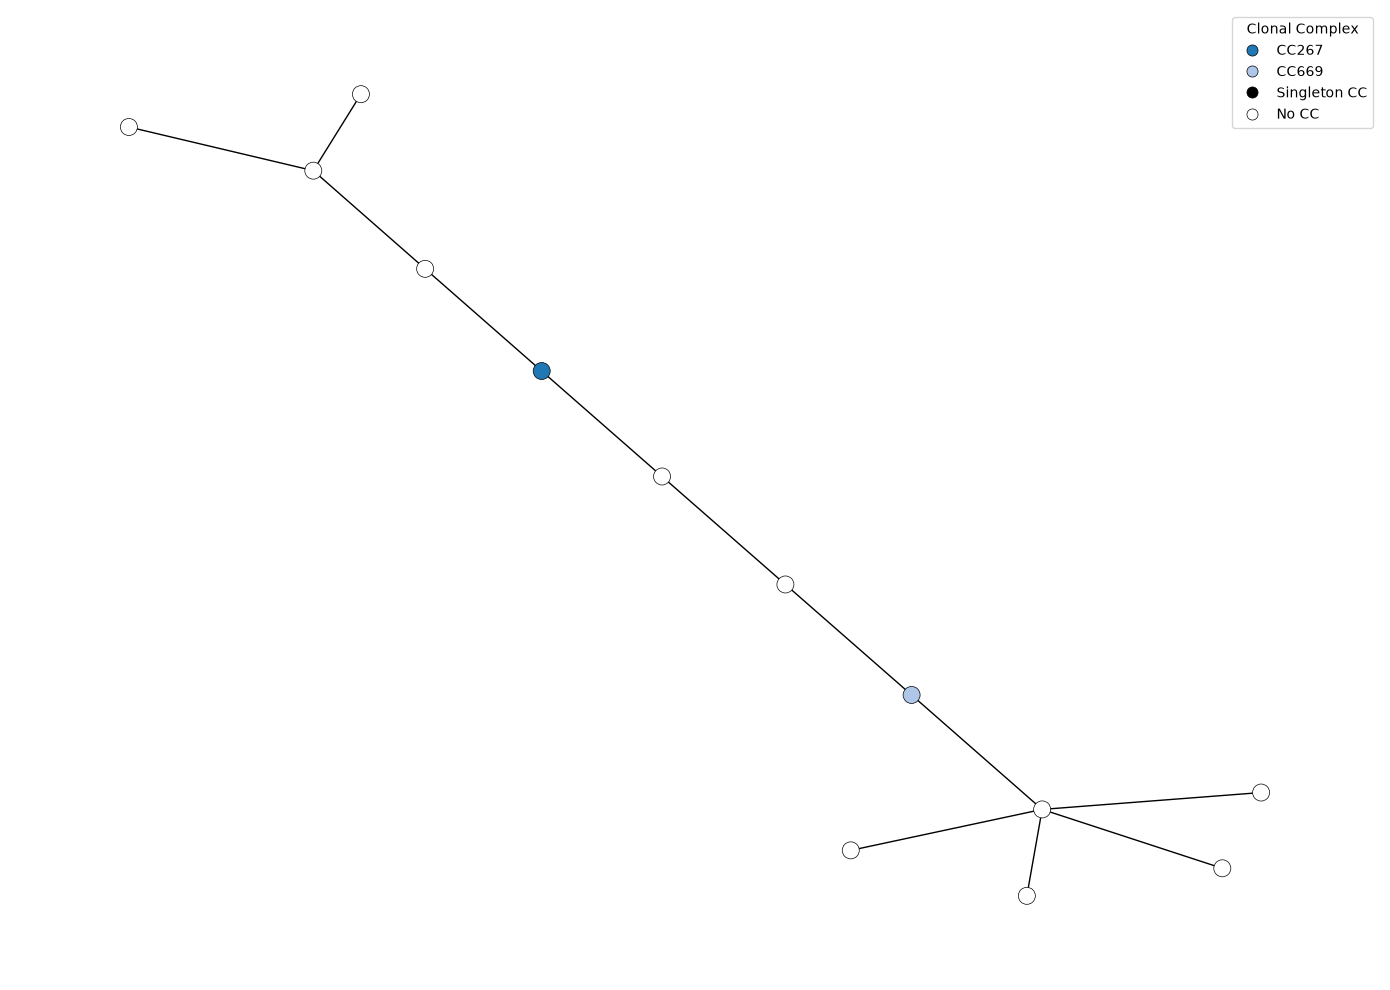

In [62]:
make_MST_allelic_distances(df_allele_dist, 'III', k_num=1, save_fName="./phylogeny/MST/Lineage_III_allelic_distances.svg")

In [63]:
df_metadata.query("CC=='CC267'").Sample

209    PNUSAL023663
Name: Sample, dtype: str

In [9]:
seq_file = pd.DataFrame([(seq.id, seq.seq) for seq in SeqIO.parse("phylogeny/core_genome.aln", "fasta")], columns=['Sample', 'Seq'])
print(len(seq_file))

snp_matrix = pd.read_csv("phylogeny/snp_matrix.csv").iloc[:-1, :-1].set_index(['snp-dists 1.2.0'])

snp_matrix.columns = [col.split('_snippy')[0] for col in snp_matrix.columns]
snp_matrix.index = [col.split('_snippy')[0] for col in snp_matrix.index.values]

df_snp_dist = convert_matrix_to_long(snp_matrix, 'SNP_dist', df_metadata)

367


In [15]:
df_snp_dist.query("acc_id1 != acc_id2 & SNP_dist <= 5").sort_values('SNP_dist').CC1.value_counts()

CC1
CC389    34
CC183     3
CC217     2
CC4       1
CC554     1
Name: count, dtype: int64

In [18]:
other_CC_samples = df_metadata.query("CC=='CC11' & Sample != 'EHS2500063659-01-00'").Sample.values
len(other_CC_samples)

7

In [19]:
df_allele_dist.query("acc_id1 != acc_id2").groupby('Group')[['Collection_date_diff_days', 'WWTP_dist_miles']].agg(['mean', 'median']).loc[['Same CC and Lineage', 'Same Lineage Only', 'Different CC and Lineage']]

Collection_date_diff_days        WWTP_dist_miles  \
                                              mean median            mean   
Group                                                                       
Same CC and Lineage                     225.958609   89.5      108.838986   
Same Lineage Only                       225.852045  114.0      119.896120   
Different CC and Lineage                246.429222  146.0      117.182827   

                                      
                              median  
Group                                 
Same CC and Lineage       117.595811  
Same Lineage Only         119.070836  
Different CC and Lineage  118.194732

In [20]:
df_snp_dist.query("Sample1=='EHS2500063659-01-00'").sort_values('SNP_dist').head()[['Sample1', 'Sample2', 'SNP_dist', 'CC2']]

,Sample1,Sample2,SNP_dist,CC2
2045,EHS2500063659-01-00,EHS2600021507-01-00,18845,NaN
1967,EHS2500063659-01-00,EHS2500075459-01-00,22812,CC90
2020,EHS2500063659-01-00,EHS2600002436-01-00,22936,ST376
2014,EHS2500063659-01-00,EHS2500089142-01-00,23642,CC570
2071,EHS2500063659-01-00,IDR2400055919-04-02,23780,ST795


In [21]:
df_snp_dist.query("(Sample1=='EHS2500063659-01-00' & CC2=='CC11') | (Sample2=='EHS2500063659-01-00' & CC1=='CC11')")[['Sample1', 'Collection date1', 'WWTP1', 'County1', 'SNP_dist', 'Sample2', 'Collection date2', 'WWTP2', 'County2']]

,Sample1,Collection date1,WWTP1,County1,SNP_dist,Sample2,Collection date2,WWTP2,County2
1972,EHS2500063659-01-00,2026-03-05,City of Batavia,Genesee,23948,EHS2500081580-01-00,2026-03-03,Village of Chittenango,Madison
1973,EHS2500063659-01-00,2026-03-05,City of Batavia,Genesee,23950,EHS2500081582-01-00,2026-01-20,Village of Chittenango,Madison
1994,EHS2500063659-01-00,2026-03-05,City of Batavia,Genesee,23968,EHS2500082382-01-00,2026-02-04,Yonkers,Westchester
2010,EHS2500063659-01-00,2026-03-05,City of Batavia,Genesee,23961,EHS2500089135-01-00,2026-01-22,Southtowns,Erie
2018,EHS2500063659-01-00,2026-03-05,City of Batavia,Genesee,24003,EHS2600002416-01-00,2026-04-14,Village of Chittenango,Madison
2065,EHS2500063659-01-00,2026-03-05,City of Batavia,Genesee,23999,IDR2400055884-04-02,2024-08-25,Brewerton,Onondaga
2066,EHS2500063659-01-00,2026-03-05,City of Batavia,Genesee,23989,IDR2400055884-04-04,2024-08-25,Brewerton,Onondaga


In [22]:
df_snp_dist.query("Sample1 in @other_CC_samples & Sample2 in @other_CC_samples")[['Sample1', 'Collection date1', 'WWTP1', 'County1', 'SNP_dist', 'Sample2', 'Collection date2', 'WWTP2', 'County2']].sort_values('SNP_dist')

,Sample1,Collection date1,WWTP1,County1,SNP_dist,Sample2,Collection date2,WWTP2,County2
3364,EHS2500081580-01-00,2026-03-03,Village of Chittenango,Madison,18,EHS2500081582-01-00,2026-01-20,Village of Chittenango,Madison
8479,IDR2400055884-04-02,2024-08-25,Brewerton,Onondaga,28,IDR2400055884-04-04,2024-08-25,Brewerton,Onondaga
7021,EHS2600002416-01-00,2026-04-14,Village of Chittenango,Madison,52,IDR2400055884-04-02,2024-08-25,Brewerton,Onondaga
7022,EHS2600002416-01-00,2026-04-14,Village of Chittenango,Madison,68,IDR2400055884-04-04,2024-08-25,Brewerton,Onondaga
3401,EHS2500081580-01-00,2026-03-03,Village of Chittenango,Madison,86,EHS2500089135-01-00,2026-01-22,Southtowns,Erie
5370,EHS2500082382-01-00,2026-02-04,Yonkers,Westchester,86,EHS2500089135-01-00,2026-01-22,Southtowns,Erie
3501,EHS2500081582-01-00,2026-01-20,Village of Chittenango,Madison,96,EHS2500089135-01-00,2026-01-22,Southtowns,Erie
3385,EHS2500081580-01-00,2026-03-03,Village of Chittenango,Madison,96,EHS2500082382-01-00,2026-02-04,Yonkers,Westchester
3485,EHS2500081582-01-00,2026-01-20,Village of Chittenango,Madison,106,EHS2500082382-01-00,2026-02-04,Yonkers,Westchester
3457,EHS2500081580-01-00,2026-03-03,Village of Chittenango,Madison,12901,IDR2400055884-04-04,2024-08-25,Brewerton,Onondaga


In [23]:
sample = 'EHS2500063659-01-00'

vcf = pysam.VariantFile(f"./results/{sample}/{sample}_snippy/snps.vcf", "r")

df_snps = pd.DataFrame(columns = ['POS', 'REF', 'ALT', 'AO', 'DP'])
i = 0

for record in vcf:
    if record.info['TYPE'][0]=='snp':
        df_snps.loc[i, :] = [record.pos, record.ref, record.alts[0], int(record.info['AO'][0]), record.info['DP']]
        i += 1

vcf.close()

In [42]:
sample = 'EHS2500081580-01-00'

vcf = pysam.VariantFile(f"./results/{sample}/{sample}_snippy/snps.vcf", "r")

df_other_snps = pd.DataFrame(columns = ['POS', 'REF', 'OTHER_ALT', 'OTHER_AO', 'OTHER_DP'])
i = 0

for record in vcf:
    if record.info['TYPE'][0]=='snp':
        df_other_snps.loc[i, :] = [record.pos, record.ref, record.alts[0], int(record.info['AO'][0]), record.info['DP']]
        i += 1

vcf.close()

In [45]:
len(df_snps), len(df_other_snps)

(66969, 67553)

In [47]:
df_compare = df_snps.merge(df_other_snps, on=['POS', 'REF'], how='outer')

In [55]:
# 56k SNPs are the same, 506 are different, 10k are unique to each sample
len(df_compare), len(df_compare.query("ALT == OTHER_ALT")), len(df_compare.query("ALT != OTHER_ALT").dropna()), len(df_compare.loc[pd.isnull(df_compare['ALT'])]), len(df_compare.loc[pd.isnull(df_compare['OTHER_ALT'])])

(77486, 56530, 506, 10517, 9933)

In [54]:
df_compare.query("ALT != OTHER_ALT").dropna()

,POS,REF,ALT,AO,DP,OTHER_ALT,OTHER_AO,OTHER_DP
48,2776,A,C,20,20,T,20,20
128,6164,A,T,20,20,G,20,20
481,21387,T,G,20,20,A,20,20
513,22527,C,T,19,19,G,20,20
740,32770,A,G,20,20,C,20,20
...,...,...,...,...,...,...,...,...
76887,2881884,C,T,20,20,G,18,18
76977,2884258,C,A,18,18,T,19,19
76984,2884381,C,G,18,18,T,19,19
77104,2888605,A,G,20,20,T,17,17


In [60]:
df_compare.loc[pd.isnull(df_compare['ALT'])]

,POS,REF,ALT,AO,DP,OTHER_ALT,OTHER_AO,OTHER_DP
8,699,T,NaN,NaN,NaN,C,20,20
9,921,T,NaN,NaN,NaN,C,20,20
11,939,G,NaN,NaN,NaN,T,20,20
16,1155,A,NaN,NaN,NaN,C,20,20
17,1215,C,NaN,NaN,NaN,T,20,20
...,...,...,...,...,...,...,...,...
77336,2897947,A,NaN,NaN,NaN,G,20,20
77399,2900464,G,NaN,NaN,NaN,A,20,20
77428,2901952,C,NaN,NaN,NaN,T,17,17
77433,2902012,T,NaN,NaN,NaN,C,16,16


In [62]:
df_compare.loc[pd.isnull(df_compare['OTHER_ALT'])]

,POS,REF,ALT,AO,DP,OTHER_ALT,OTHER_AO,OTHER_DP
5,609,G,A,20,20,NaN,NaN,NaN
14,1084,T,C,20,20,NaN,NaN,NaN
27,2077,G,A,20,20,NaN,NaN,NaN
28,2104,A,C,20,20,NaN,NaN,NaN
40,2518,T,C,20,20,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
77411,2901251,A,G,20,20,NaN,NaN,NaN
77412,2901282,A,C,20,20,NaN,NaN,NaN
77430,2901994,A,C,18,18,NaN,NaN,NaN
77444,2902456,A,G,20,20,NaN,NaN,NaN


# Clusters

In [32]:
def add_new_cluster_annotations(df, dist_col, dist_max=6, cluster_num_start=1):

    parent = {}
    
    def find(x):
        parent.setdefault(x, x)
        if parent[x] != x:
            parent[x] = find(parent[x])
        return parent[x]
    
    def union(x, y):
        x_root = find(x)
        y_root = find(y)
    
        if x_root != y_root:
            parent[y_root] = x_root
    
    
    # Build connected components
    for i, row in df.iterrows():
        if row[dist_col] <= dist_max:
            union(row['Sample1'], row['Sample2'])
    
    
    # Sample -> root
    sample_to_root = {
        sample: find(sample)
        for sample in parent
    }
    
    # Root -> cluster ID
    root_to_cluster = {
        root: f"CLUSTER_{cluster_id}"
        for cluster_id, root in enumerate(set(sample_to_root.values()), start=cluster_num_start)
    }
    
    # Sample -> cluster ID
    cluster_map = {
        sample: root_to_cluster[root]
        for sample, root in sample_to_root.items()
    }
    
    df['Cluster1'] = df['Sample1'].map(cluster_map)
    df['Cluster2'] = df['Sample2'].map(cluster_map)

    # to compare between existing clustering results and these new results
    df['Same_Cluster'] = (df['Cluster1']==df['Cluster2']).astype(int)
    df.loc[pd.isnull(df['Cluster1']) | pd.isnull(df['Cluster2']), 'Same_Cluster'] = np.nan

    return df, cluster_map

In [34]:
df_allele_dist_cluster_annot, cluster_map = add_new_cluster_annotations(df_allele_dist, 'Allele_Diff', dist_max=6, cluster_num_start=1)

df_cluster_map = pd.DataFrame(cluster_map, index=[0]).T.reset_index()
df_cluster_map.columns = ['Sample', 'Cluster_ID']
df_cluster_map['acc_id'] = df_cluster_map['Sample'].str.split('-').str[0]

df_clustered_samples = df_allele_dist_cluster_annot.query("Same_Cluster==1")

print(f"{df_clustered_samples.dropna(subset='Cluster1').Cluster1.nunique()} with {len(set(df_clustered_samples.Sample1).union(df_clustered_samples.Sample2))} samples")

18 with 68 samples


In [35]:
df_allele_dist_cluster_annot.groupby('Same_Cluster')[['Collection_date_diff_days', 'WWTP_dist_miles']].agg(['mean', 'median']).loc[[1, 0]]

Collection_date_diff_days        WWTP_dist_miles            
                                  mean median            mean      median
Same_Cluster                                                             
1.0                         153.836364   60.0       47.551526    0.000000
0.0                         280.921439  182.0      116.387979  129.520556

In [270]:
df_metadata.loc[pd.isnull(df_metadata['CC'])]

,SCHEME,STATUS,SCORE,ALLELES,abcZ,bglA,cat,dapE,dat,ldh,...,MLST7,acc_id,Collection date,WWTP,County,wwtp_latitude,wwtp_longitude,geometry,sample_type,WWTP_Cases
40,listeria_2,OK,82,abcZ(92);bglA(~401);cat(227);dapE(563);dat(147...,92,401,227,563,147,661,...,lhkA(298),PNUSAL025271,NaT,NaN,Rockland,NaN,NaN,NaN,Blood,NaN
57,listeria_2,NOVEL,90,abcZ(20);bglA(33);cat(21);dapE(83);dat(17);ldh...,20,33,21,83,17,31,...,lhkA(56),PNUSAL026439,NaT,NaN,Nassau,NaN,NaN,NaN,Blood,NaN
85,listeria_2,NOVEL,90,abcZ(93);bglA(10);cat(62);dapE(4);dat(210);ldh...,93,10,62,4,210,2,...,lhkA(1),IDR2400055889,2024-08-22,Binghamton - North,Broome,42.10,-75.96,MULTIPOLYGON (((-75.90344668287528 42.13788072...,NaN,3.0
102,listeria_2,OK,74,abcZ(~413);bglA(269);cat(268);dapE(50);dat(~16...,413,269,268,50,162,114,...,lhkA(~273),EHS2600010400,2026-03-18,Town of Victor and Town Of Farmington,Monroe,42.98,-77.38,MULTIPOLYGON (((-77.36337879579654 42.95818498...,NaN,1.0
108,listeria_2,OK,82,abcZ(579);bglA(~399);cat(313);dapE(462);dat(~3...,579,399,313,462,307,573,...,lhkA(502),PNUSAL024917,NaT,NaN,Out-Of-State,NaN,NaN,NaN,Blood,NaN
128,listeria_2,NOVEL,90,abcZ(5);bglA(10);cat(16);dapE(68);dat(1);ldh(2...,5,10,16,68,1,2,...,lhkA(92),PNUSAL020033,NaT,NaN,Albany,NaN,NaN,NaN,Blood,NaN
131,listeria_2,OK,86,abcZ(5);bglA(5);cat(8);dapE(18);dat(~38);ldh(7...,5,5,8,18,38,7,...,lhkA(1),PNUSAL025548,NaT,NaN,Ontario,NaN,NaN,NaN,Blood,NaN
155,listeria_2,NOVEL,90,abcZ(22);bglA(58);cat(52);dapE(24);dat(22);ldh...,22,58,52,24,22,123,...,lhkA(46),PNUSAL025547,NaT,NaN,Chemung,NaN,NaN,NaN,Blood venous,NaN
161,listeria_2,NOVEL,90,abcZ(92);bglA(117);cat(127);dapE(113);dat(348)...,92,117,127,113,348,380,...,lhkA(298),EHS2500055014,2026-01-28,Monticello,Sullivan,41.64,-74.67,POLYGON ((-74.63828235351482 41.64043041335354...,NaN,15.0
244,listeria_2,OK,86,abcZ(7);bglA(14);cat(10);dapE(~174);dat(1);ldh...,7,14,10,174,1,8,...,lhkA(1),EHS2500089139,2026-02-03,Southtowns,Erie,42.79,-78.85,POLYGON ((-78.84587867817086 42.73928859841985...,NaN,12.0


In [268]:
pd.DataFrame(df_metadata.dropna(subset='WWTP').groupby('CC')['WWTP'].nunique())

,WWTP
CC,
CC1,8
CC11,5
CC14,2
CC155,1
CC183,1
CC195,1
CC2,1
CC204,3
CC207,1


# Roary Pangenome Analysis

In [228]:
gene_matrix = pd.read_csv("roary_results/gene_presence_absence.Rtab", sep='\t', index_col=[0])
gene_info = pd.read_csv("roary_results/gene_presence_absence.csv")

/var/folders/hw/l52lfnfj4gg_67vzk3vwm9br0000gq/T/ipykernel_38334/3135929894.py:2: DtypeWarning: Columns (0: QC, 1: EHS2500002694-01-01, 2: EHS2500002739-01-01, 3: EHS2500012315-04-01, 4: EHS2500012412-04-01, 5: EHS2500012533-04-01, 6: EHS2500012567-04-01, 7: EHS2500019157-04-01, 8: EHS2500055010-01-01, 9: EHS2500055012-01-02, 10: EHS2500055013-01-00, 11: EHS2500055088-01-00, 12: EHS2500055583-01-00, 13: EHS2500061796-01-00, 14: EHS2500069202-01-02, 15: EHS2500069203-04-01, 16: EHS2500069330-01-00, 17: EHS2500069334-01-00, 18: EHS2500069717-01-01, 19: EHS2500075458-01-00, 20: EHS2500075459-01-00, 21: EHS2500075469-01-00, 22: EHS2500075619-01-00, 23: EHS2500075627-01-00, 24: EHS2500075631-01-00, 25: EHS2500081580-01-00, 26: EHS2500081582-01-00, 27: EHS2500081583-01-01, 28: EHS2500081585-01-00, 29: EHS2500081604-01-01, 30: EHS2500081780-01-00, 31: EHS2500081782-01-00, 32: EHS2500081783-01-00, 33: EHS2500081784-01-00, 34: EHS2500081785-01-02, 35: EHS2500081786-01-00, 36: EHS2500081868-01-0

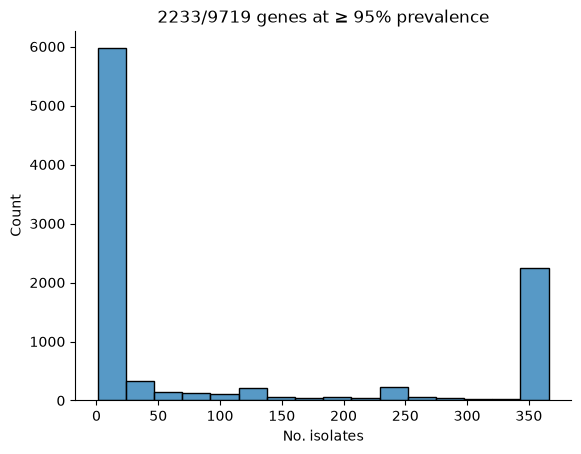

In [229]:
# core genome is 2000-2250 genes

core_gene_prevalence_thresh = 0.95
core_genes = gene_info.loc[gene_info['No. isolates'] >= int(core_gene_prevalence_thresh*gene_matrix.shape[1])]

plt.title(f"{len(core_genes)}/{len(gene_info)} genes at ≥ {int(core_gene_prevalence_thresh*100)}% prevalence")

sns.histplot(data=gene_info,
             x='No. isolates'
            )

sns.despine()
plt.show()

In [237]:
df_samples = pd.DataFrame({'Sample': gene_matrix.columns})

trait_cols = ['Lineage', 'WWTP', 'Sample_Origin']

df_samples = df_samples.merge(df_metadata[['Sample', 'Lineage', 'WWTP']])
df_samples['Sample_Origin'] = df_samples['Sample'].str.startswith('PN').map({True: 'Clinical', False: 'Wastewater'})

# scoary requires the isolate column name to be Name
df_samples.rename(columns={'Sample': 'Name'}, inplace=True)

In [233]:
df_samples.Sample_Origin.value_counts()

Sample_Origin
Clinical      235
Wastewater    131
Name: count, dtype: int64

In [234]:
df_samples.WWTP.value_counts()

WWTP
Baldwinsville                            16
Monticello                               15
Southtowns                               12
Saratoga Co SD No 1                      11
Utica - City                             11
Yonkers                                   9
Bath                                      8
Village of Chittenango                    8
Northwest Quadrant                        4
Ossining                                  4
Meadowbrook/Limestone                     4
City of Batavia                           3
Utica - Suburbs                           3
Brewerton                                 3
Binghamton - North                        3
Village of Lowville                       2
Whitehall                                 2
South Fallsburg                           2
Harriman                                  2
City of Oneonta                           1
Herkimer County SD                        1
Norwich                                   1
Town of Bethlehem          

In [242]:
trait_freq_thresh = 10

df_samples_for_scoary = df_samples[['Name']]

# for scoary, all traits must be dummy encoded
for trait in trait_cols:
    df_dummy = pd.get_dummies(df_samples[trait], prefix=trait)

    for col in df_dummy.columns:
        df_dummy[col] = df_dummy[col].map({True: 1, False: 0})

        # scoary won't skip traits that have only 1 representative isolate. Enforce some minimum because if too few isolates have it, the results are not reliable
        if df_dummy[col].sum() < trait_freq_thresh:
            print(f"Removing {col} because it has fewer than {trait_freq_thresh} isolates")
            del df_dummy[col]

    df_samples_for_scoary = pd.concat([df_samples_for_scoary, df_dummy], axis=1)

df_samples_for_scoary.to_csv("./roary_results/traits.csv", index=False)

Removing WWTP_Amsterdam because it has fewer than 10 isolates
Removing WWTP_Bath because it has fewer than 10 isolates
Removing WWTP_Binghamton - North because it has fewer than 10 isolates
Removing WWTP_Brewerton because it has fewer than 10 isolates
Removing WWTP_City of Batavia because it has fewer than 10 isolates
Removing WWTP_City of Oneonta because it has fewer than 10 isolates
Removing WWTP_Harriman because it has fewer than 10 isolates
Removing WWTP_Herkimer County SD because it has fewer than 10 isolates
Removing WWTP_Meadowbrook/Limestone because it has fewer than 10 isolates
Removing WWTP_Northwest Quadrant because it has fewer than 10 isolates
Removing WWTP_Norwich because it has fewer than 10 isolates
Removing WWTP_Orangetown because it has fewer than 10 isolates
Removing WWTP_Ossining because it has fewer than 10 isolates
Removing WWTP_Rensselaer because it has fewer than 10 isolates
Removing WWTP_Rockland Co SD because it has fewer than 10 isolates
Removing WWTP_South F

In [243]:
df_samples_for_scoary

,Name,Lineage_I,Lineage_II,Lineage_III,WWTP_Baldwinsville,WWTP_Monticello,WWTP_Saratoga Co SD No 1,WWTP_Southtowns,WWTP_Utica - City,Sample_Origin_Clinical,Sample_Origin_Wastewater
0,EHS2500002694-01-01,1,0,0,0,0,0,0,0,0,1
1,EHS2500002739-01-01,0,1,0,0,0,0,0,0,0,1
2,EHS2500012315-04-01,1,0,0,0,0,0,0,0,0,1
3,EHS2500012412-04-01,1,0,0,0,0,0,0,0,0,1
4,EHS2500012533-04-01,0,1,0,0,0,1,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...
361,PNUSAL027034,1,0,0,0,0,0,0,0,1,0
362,PNUSAL027068,1,0,0,0,0,0,0,0,1,0
363,PNUSAL027080,0,1,0,0,0,0,0,0,1,0
364,PNUSAL027114,1,0,0,0,0,0,0,0,1,0


In [245]:
pval_thresh = 0.05
df_scoary_significant = []

for trait in df_samples_for_scoary.columns[1:]:

    df_trait_scoary = pd.read_csv(f"roary_results/{trait}_05_11_2026_1423.results.csv")
    df_trait_scoary['Trait'] = trait

    df_scoary_significant.append(df_trait_scoary.query("Bonferroni_p <= @pval_thresh"))

df_scoary_significant = pd.concat(df_scoary_significant)

In [248]:
df_scoary_significant.query("~Trait.str.contains('Lineage')")[['Trait', 'Gene', 'Non-unique Gene name', 'Annotation', 'Odds_ratio', 'Bonferroni_p', 'Number_pos_present_in', 'Number_neg_present_in', 'Number_pos_not_present_in', 'Number_neg_not_present_in']].Trait.unique()

<StringArray>
[      'WWTP_Baldwinsville',          'WWTP_Monticello',
   'Sample_Origin_Clinical', 'Sample_Origin_Wastewater']
Length: 4, dtype: str

In [256]:
# get genes associated with certain WWTPs
genes_assoc_with_wwtps = df_scoary_significant.query("Trait.str.contains('WWTP')").Gene.unique()
print(len(genes_assoc_with_wwtps))
# remove genes that are also associated with Lineage because certain Lineages are associated with WWTPs, so Lineage is a confounder
genes_assoc_with_wwtps = list(set(genes_assoc_with_wwtps) - set(df_scoary_significant.query("Gene in @genes_assoc_with_wwtps & Trait.str.contains('Lineage')").Gene))
print(len(genes_assoc_with_wwtps))

49
43


In [261]:
df_scoary_significant.query("Trait.str.contains('WWTP') & Gene in @genes_assoc_with_wwtps")[['Trait', 'Gene', 'Non-unique Gene name', 'Annotation', 'Odds_ratio', 'Bonferroni_p', 'Number_pos_present_in', 'Number_neg_present_in', 'Number_pos_not_present_in', 'Number_neg_not_present_in']]

,Trait,Gene,Non-unique Gene name,Annotation,Odds_ratio,Bonferroni_p,Number_pos_present_in,Number_neg_present_in,Number_pos_not_present_in,Number_neg_not_present_in
0,WWTP_Baldwinsville,group_5983,DUF1642 domain-containing protein,DUF1642 domain-containing protein,inf,6.465614e-04,5,0,11,350
1,WWTP_Baldwinsville,Lin1248 protein,NaN,Lin1248 protein,158.636364,3.780862e-03,5,1,11,349
2,WWTP_Baldwinsville,group_5984,yopX,YopX protein domain-containing protein,158.636364,3.780862e-03,5,1,11,349
3,WWTP_Baldwinsville,group_5986,hypothetical protein,hypothetical protein,158.636364,3.780862e-03,5,1,11,349
4,WWTP_Baldwinsville,group_5987,hypothetical protein,hypothetical protein,158.636364,3.780862e-03,5,1,11,349
5,WWTP_Baldwinsville,group_5988,hypothetical protein,hypothetical protein,158.636364,3.780862e-03,5,1,11,349
6,WWTP_Baldwinsville,Gp76,NaN,Gp76,158.636364,3.780862e-03,5,1,11,349
7,WWTP_Baldwinsville,group_2718,hypothetical protein,hypothetical protein,79.090909,1.289645e-02,5,2,11,348
8,WWTP_Baldwinsville,group_3650,yajC,Preprotein translocase subunit YajC,79.090909,1.289645e-02,5,2,11,348
9,WWTP_Baldwinsville,group_3980,Uncharacterized protein Lin1253/Lin1744,Uncharacterized protein Lin1253/Lin1744,79.090909,1.289645e-02,5,2,11,348


In [263]:
df_scoary_significant.query("Gene=='group_5984'")

,Gene,Non-unique Gene name,Annotation,Number_pos_present_in,Number_neg_present_in,Number_pos_not_present_in,Number_neg_not_present_in,Sensitivity,Specificity,Odds_ratio,Naive_p,Bonferroni_p,Benjamini_H_p,Max_Pairwise_comparisons,Max_supporting_pairs,Max_opposing_pairs,Best_pairwise_comp_p,Worst_pairwise_comp_p,Trait
2,group_5984,yopX,YopX protein domain-containing protein,5,1,11,349,31.25,99.714286,158.636364,4.796831e-07,0.003781,0.00054,2,1,1,1.0,1.0,WWTP_Baldwinsville


In [264]:
df_metadata.query("WWTP in ['Baldwinsville']")[['Sample', 'acc_id', 'Collection date', 'Lineage', 'CC']].sort_values('Lineage')

,Sample,acc_id,Collection date,Lineage,CC
97,EHS2600037161-01-00,EHS2600037161,2026-08-31,I,CC4
118,IDR2400047782-04-01,IDR2400047782,2024-07-14,I,CC217
135,EHS2600002435-01-00,EHS2600002435,2026-03-30,I,CC554
146,EHS2600037158-01-00,EHS2600037158,2026-08-24,I,CC4
160,EHS2600002437-01-00,EHS2600002437,2026-03-02,I,CC554
278,EHS2600002440-01-00,EHS2600002440,2026-02-17,I,CC554
283,EHS2600002438-01-00,EHS2600002438,2026-03-09,I,CC554
288,EHS2600016102-01-00,EHS2600016102,2026-04-13,I,CC554
323,IDR2400047782-04-02,IDR2400047782,2024-07-14,I,CC217
335,EHS2600016104-01-00,EHS2600016104,2026-04-20,I,CC554


In [141]:
pan_genome = [(seq.description, seq.seq) for seq in SeqIO.parse("roary_results/pan_genome_reference.fa", "fasta")]

total_length = 0

for _, seq in pan_genome:
    total_length += len(seq)

len(pan_genome), total_length

(9719, 7660089)

In [144]:
for name, seq in pan_genome:

    if name.endswith('group_396') or name.endswith('group_792'):
        print(name, seq)

MCPMED_00328 group_396 ATGGCTACGAAGTCGACTGTAGAAAACTTATACATCGCTGGGACTAAACAACTTACGGGTTTTGGGCGTGAATATGAATACTTACTACAACATGGTTATACTTATGATGTAAAAACAAGTACAATGAAGTTGAAGAAATGA
BGHFED_00836 group_792 ATGAAGAATAATAAACTTATCATTTTAGTAGTTATTTGTTTGTTTCTACAAGCAATATTATTCATGGCCTTTGACTTCCCGTTCAAAACATTACCAATACTAGATGGATTTCCAGTAGGATTAGCCACACCGGTAGTAACCAGATTATTGCTTTACTGGTATCTCCCGATTATTGCTTTACTGGTATCTCCCGATTATTGCTTTTAG


In [140]:
pan_genome[0]

('MCPMED_00001_MCPMED_00001 group_596',
 Seq('ATGTATACGCCGATTGCTATTTCCGCCTTACCAGTGACAGTGAACTATTTAGAT...TAA'))

In [183]:
fastq_files = pd.read_csv("../fastq_files.txt", sep='\t', header=None)
fastq_files['base_name'] = [os.path.basename(fName).split('_')[0] for fName in fastq_files[0].values]
len(fastq_files)

730

In [184]:
fastq_files.query("base_name.str.contains('PNUSAL015131')")

,0,base_name
316,gs://bact-outbreak-1-nysdohwc/sanjana/MOAP/inp...,PNUSAL015131
317,gs://bact-outbreak-1-nysdohwc/sanjana/MOAP/inp...,PNUSAL015131


In [187]:
set(os.listdir("results")) - set(fastq_files.base_name)

{'PNUSAL026348'}

In [195]:
# # gcloud_dir = "gs://bact-outbreak-1-nysdohwc/sanjana/MOAP/input"

# fNames = glob.glob(f"results/*/*.fastq.gz")
# print(len(fNames))

# for fName in fNames:
#     base_name = os.path.basename(fName)

#     if base_name not in fastq_files.base_name.values:
#         subprocess.run(f"gcloud storage cp {fName} {gcloud_dir}/{base_name}", shell=True)